### **Импорты и чтение csv**

In [29]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, accuracy_score, f1_score, roc_auc_score, classification_report

In [30]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test_features.csv')

In [31]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   patient_id                     800 non-null    int64  
 1   Возраст                        800 non-null    int64  
 2   Пол_мужской                    800 non-null    int64  
 3   ИМТ                            800 non-null    float64
 4   Окружность_талии_см            800 non-null    float64
 5   САД_мм_рт_ст                   800 non-null    float64
 6   ДАД_мм_рт_ст                   800 non-null    float64
 7   Пульсовое_давление             800 non-null    float64
 8   Глюкоза_натощак_ммоль_л        800 non-null    float64
 9   HbA1c_%                        800 non-null    float64
 10  ЛПНП_ммоль_л                   765 non-null    float64
 11  ЛПВП_ммоль_л                   755 non-null    float64
 12  Триглицериды_ммоль_л           754 non-null    float64
 13  С

In [32]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   patient_id                     200 non-null    int64  
 1   Возраст                        200 non-null    int64  
 2   Пол_мужской                    200 non-null    int64  
 3   ИМТ                            200 non-null    float64
 4   Окружность_талии_см            200 non-null    float64
 5   САД_мм_рт_ст                   200 non-null    float64
 6   ДАД_мм_рт_ст                   200 non-null    float64
 7   Пульсовое_давление             200 non-null    float64
 8   Глюкоза_натощак_ммоль_л        200 non-null    float64
 9   HbA1c_%                        200 non-null    float64
 10  ЛПНП_ммоль_л                   190 non-null    float64
 11  ЛПВП_ммоль_л                   189 non-null    float64
 12  Триглицериды_ммоль_л           185 non-null    float64
 13  С

In [33]:
train.nunique(dropna=True)

patient_id                       800
Возраст                           26
Пол_мужской                        2
ИМТ                              584
Окружность_талии_см              665
САД_мм_рт_ст                     713
ДАД_мм_рт_ст                     677
Пульсовое_давление               732
Глюкоза_натощак_ммоль_л          680
HbA1c_%                          164
ЛПНП_ммоль_л                     649
ЛПВП_ммоль_л                     557
Триглицериды_ммоль_л             529
СКФ_мл_мин                       675
Курение                            2
Физическая_активность_мин_нед    619
prediction                         2
Статус_глюкозы                     3
Доклинический_риск                 2
dtype: int64

### **Разделение признаков на числовые и категориальные**

In [34]:
target = 'prediction'
catcols = ['Пол_мужской', 'Курение', 'Статус_глюкозы', 'Доклинический_риск']
numcols = [col for col in train.columns if col not in ['patient_id', target] + catcols]
numcols

['Возраст',
 'ИМТ',
 'Окружность_талии_см',
 'САД_мм_рт_ст',
 'ДАД_мм_рт_ст',
 'Пульсовое_давление',
 'Глюкоза_натощак_ммоль_л',
 'HbA1c_%',
 'ЛПНП_ммоль_л',
 'ЛПВП_ммоль_л',
 'Триглицериды_ммоль_л',
 'СКФ_мл_мин',
 'Физическая_активность_мин_нед']

In [35]:
train[target].value_counts()

prediction
0    655
1    145
Name: count, dtype: int64

### **Удаление выбросов (IQR)**

In [36]:
q1 = train[numcols].quantile(0.25)
q3 = train[numcols].quantile(0.75)
iqr = q3 - q1

In [37]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

In [38]:
# NaN при сравнении даёт False, поэтому пропуски не считаются выбросами
outliers = (train[numcols] < lower) | (train[numcols] > upper)
outliers.sum()

Возраст                          0
ИМТ                              2
Окружность_талии_см              3
САД_мм_рт_ст                     1
ДАД_мм_рт_ст                     8
Пульсовое_давление               7
Глюкоза_натощак_ммоль_л          2
HbA1c_%                          5
ЛПНП_ммоль_л                     6
ЛПВП_ммоль_л                     3
Триглицериды_ммоль_л             0
СКФ_мл_мин                       4
Физическая_активность_мин_нед    5
dtype: int64

In [39]:
print('Строк с выбросами:', outliers.any(axis=1).sum())
train = train[~outliers.any(axis=1)].reset_index(drop=True)
train.shape

Строк с выбросами: 44


(756, 19)

In [40]:
train[target].value_counts()

prediction
0    626
1    130
Name: count, dtype: int64

### **Заполнение пропусков средним**

In [41]:
nan_cols = train.columns[train.isna().any()].to_list()
nan_cols

['ЛПНП_ммоль_л', 'ЛПВП_ммоль_л', 'Триглицериды_ммоль_л', 'СКФ_мл_мин']

In [42]:
train.isna().sum()

patient_id                        0
Возраст                           0
Пол_мужской                       0
ИМТ                               0
Окружность_талии_см               0
САД_мм_рт_ст                      0
ДАД_мм_рт_ст                      0
Пульсовое_давление                0
Глюкоза_натощак_ммоль_л           0
HbA1c_%                           0
ЛПНП_ммоль_л                     33
ЛПВП_ммоль_л                     43
Триглицериды_ммоль_л             43
СКФ_мл_мин                       42
Курение                           0
Физическая_активность_мин_нед     0
prediction                        0
Статус_глюкозы                    0
Доклинический_риск                0
dtype: int64

In [43]:
train[nan_cols].describe()

,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин
count,723.000000,713.000000,713.000000,714.000000
mean,2.979022,1.494645,1.027884,96.353501
std,0.619819,0.301057,0.474522,9.915348
min,1.291000,0.633000,0.400000,70.520000
25%,2.564000,1.279000,0.619000,89.760000
50%,2.987000,1.502000,0.994000,96.205000
75%,3.400000,1.712000,1.379000,102.980000
max,4.677000,2.357000,2.479000,122.680000


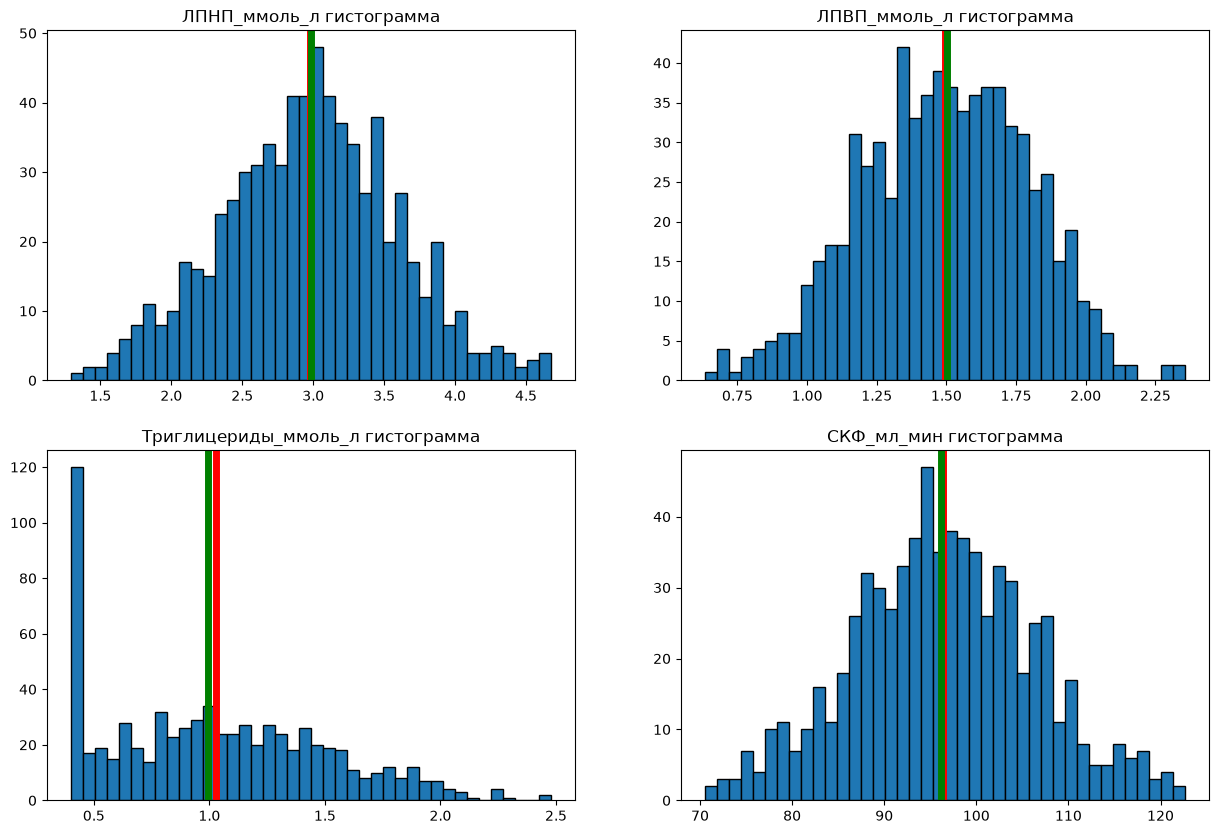

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()
for idx, nan_col in enumerate(nan_cols):
    axes[idx].hist(train[nan_col].dropna(), bins=40, edgecolor='black')
    axes[idx].axvline(train[nan_col].dropna().mean(), color='red', linewidth=5)
    axes[idx].axvline(train[nan_col].dropna().median(), color='green', linewidth=5)
    axes[idx].set_title(f'{nan_col} гистограмма')
plt.show()

In [45]:
# средние считаем только по train и ими же заполняем test
means = train[numcols].mean()
train[numcols] = train[numcols].fillna(means)
test[numcols] = test[numcols].fillna(means)

In [46]:
print('Пропусков в train:', train.isna().sum().sum())
print('Пропусков в test:', test.isna().sum().sum())

Пропусков в train: 0
Пропусков в test: 0


### **Нормализация через StandardScaler**

In [47]:
features = numcols + catcols
X = train[features]
y = train[target]
X_submit = test[features]

In [48]:
# scaler обучаем на train и применяем тот же к test_features
scaler = StandardScaler()
X = scaler.fit_transform(X)
X_submit = scaler.transform(X_submit)

### **Разделение на train / val / test**

In [49]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)

In [50]:
print('train:', X_train.shape, 'доля класса 1:', round(y_train.mean(), 3))
print('val:  ', X_val.shape, 'доля класса 1:', round(y_val.mean(), 3))
print('test: ', X_test.shape, 'доля класса 1:', round(y_test.mean(), 3))

train: (529, 17) доля класса 1: 0.172
val:   (113, 17) доля класса 1: 0.168
test:  (114, 17) доля класса 1: 0.175


### **Обучение модели (1 слой, 32 нейрона, ReLU, 150 эпох)**

In [51]:
model = MLPClassifier(hidden_layer_sizes=(32,), activation='relu', solver='adam', random_state=42)
epochs = 150

In [52]:
# один вызов partial_fit = одна эпоха, после каждой считаем loss на train и val
train_loss, val_loss = [], []
for epoch in range(epochs):
    model.partial_fit(X_train, y_train, classes=[0, 1])
    train_loss.append(log_loss(y_train, model.predict_proba(X_train)))
    val_loss.append(log_loss(y_val, model.predict_proba(X_val)))

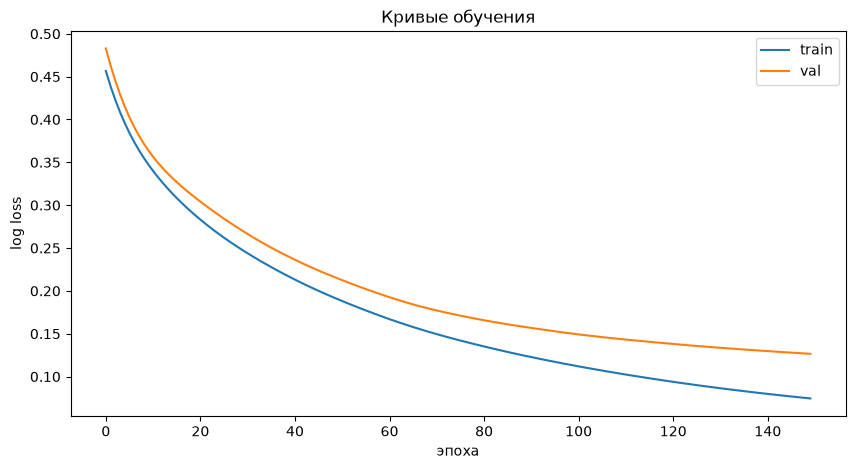

In [53]:
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='train')
plt.plot(val_loss, label='val')
plt.xlabel('эпоха')
plt.ylabel('log loss')
plt.title('Кривые обучения')
plt.legend()
plt.show()

### **Оценка на val и test**

In [54]:
for name, X_part, y_part in [('val', X_val, y_val), ('test', X_test, y_test)]:
    pred = model.predict(X_part)
    proba = model.predict_proba(X_part)[:, 1]
    print(f'{name}: accuracy = {accuracy_score(y_part, pred):.3f}, '
          f'f1 = {f1_score(y_part, pred):.3f}, roc_auc = {roc_auc_score(y_part, proba):.3f}')

val: accuracy = 0.947, f1 = 0.824, roc_auc = 0.984
test: accuracy = 0.939, f1 = 0.811, roc_auc = 0.975


In [55]:
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96        94
           1       0.88      0.75      0.81        20

    accuracy                           0.94       114
   macro avg       0.92      0.86      0.89       114
weighted avg       0.94      0.94      0.94       114



### **Предсказания для test_features.csv**

In [56]:
submission = pd.DataFrame({
    'patient_id': test['patient_id'],
    'prediction': model.predict(X_submit),
})
submission.head()

,patient_id,prediction
0,2,0
1,3,0
2,8,0
3,18,0
4,19,0


In [57]:
submission['prediction'].value_counts()

prediction
0    173
1     27
Name: count, dtype: int64

### **Сохранение в outputs/task1_predictions.csv**

In [58]:
submission.to_csv('outputs/task1_predictions.csv', index=False)

In [59]:
saved = pd.read_csv('outputs/task1_predictions.csv')
print('Файл сохранён:', saved.shape)

Файл сохранён: (200, 2)


### **Описание решения**

1. **Данные.** `train.csv` (800 пациентов, 17 признаков, таргет `prediction`, класс 1 ≈ 18%) и `test_features.csv` (200 пациентов, те же признаки без таргета).
2. **Признаки.** Числовые: возраст, ИМТ, давление, глюкоза, липиды, СКФ, активность. Категориальные (бинарные/порядковые): пол, курение, статус глюкозы, доклинический риск. `patient_id` в обучении не участвует.
3. **Выбросы.** Метод IQR (границы Q1 − 1.5·IQR и Q3 + 1.5·IQR) по числовым признакам, пропуски выбросами не считаются. Удалено 44 строки из train, строки test_features не удаляются, так как для каждой нужно предсказание.
4. **Пропуски.** Колонки ЛПНП, ЛПВП, триглицериды и СКФ заполнены средними, посчитанными по train. Теми же средними заполнен test_features.
5. **Нормализация.** `StandardScaler`, обученный на train и применённый к test_features.
6. **Разбиение.** train / val / test = 70 / 15 / 15 со стратификацией по таргету.
7. **Модель.** `MLPClassifier`: один скрытый слой из 32 нейронов, ReLU, оптимизатор Adam, 150 эпох (по одному `partial_fit` на эпоху). Loss на val снижается до последней эпохи, переобучения не видно.
8. **Качество на отложенном test:** accuracy ≈ 0.94, F1 (класс 1) ≈ 0.81, ROC-AUC ≈ 0.975.
9. **Результат.** Предсказания для test_features сохранены в `outputs/task1_predictions.csv` с колонками `patient_id` и `prediction`: 200 строк, пропусков нет.
